# A camera survey with partworth (public data)

[Open in Colab](https://colab.research.google.com/github/kojikojikojikoji/partworth/blob/main/examples/camera.ipynb)

This notebook runs partworth on real survey data. The `camera` data comes from a
published study of digital cameras (Allenby, Brazell, Howell and Rossi, 2014,
"Economic valuation of product features", Quantitative Marketing and Economics 12(4)).
332 people each answered 16 questions. Every question showed four cameras and a
"none of these" option.

The data is part of the R package [bayesm](https://cran.r-project.org/package=bayesm),
which is GPL. partworth does not include it. `load_camera()` downloads it from CRAN the
first time you run it.

## What this notebook shows

1. The same steps as the [retail survey notebook](retail_survey.ipynb), on real answers
   instead of dummy data.
2. What each feature is worth in US dollars, with a 90% credible interval.
3. How much a feature can add to the price before the product loses share. The answer
   is a probability over the posterior draws.
4. A check on questions the model did not see. The
   [validation report](../validation/results/camera_report.md) runs R bayesm on the same
   split, so the two packages can be compared.

A Japanese version of this notebook is in [camera_ja.ipynb](camera_ja.ipynb).

## Setup

```
pip install "partworth[nutpie,datasets]" "matplotlib>=3.10"
```

In Google Colab, add a code cell at the top, run the same line with `%pip` in place of
`pip`, and then run the rest. partworth needs Python 3.12 or later.

The next cell also sets the look of the charts.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import partworth as pw
from partworth.datasets import load_camera

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#E6E6E6", "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titlesize": 11,
})
MAIN, ACCENT, GREY = "#0F6E84", "#D9793D", "#B8BDC4"
FEATURES = ["pixels", "zoom", "video", "swivel", "wifi"]

## 1. The data

`load_camera()` returns the answers as `ChoiceData`. The coding follows bayesm, with one
difference. Here the price effect is kept negative for every respondent. bayesm lets it
take either sign, as `load_camera(price_sign=None)` does.

- `brand` has four levels. Canon is the reference, so the other brands are measured
  against Canon.
- The five features (`pixels`, `zoom`, `video`, `swivel`, `wifi`) are "yes" or "no".
- `price` is in hundreds of US dollars, from 0.79 to 2.79 (79 to 279 dollars). It is not
  centred or scaled, so one unit is 100 dollars.

In [2]:
data = load_camera()          # downloaded from CRAN on first use
data

ChoiceData(respondents=332, max_tasks=16, max_alternatives=5, params=10, covariates=0)

In [3]:
data.describe().round(3)

,attribute,level,shown,chosen,rate
0,brand,canon,4948,1108,0.224
1,brand,sony,5366,975,0.182
2,brand,nikon,5454,1058,0.194
3,brand,panasonic,5480,828,0.151
4,pixels,no,10557,1509,0.143
5,pixels,yes,10691,2460,0.230
6,zoom,no,10394,1482,0.143
7,zoom,yes,10854,2487,0.229
8,video,no,10625,1554,0.146
9,video,yes,10623,2415,0.227


The none option was chosen in about a quarter of the questions. The choice rate falls
fast with price: 46% at 79 dollars, 4% at 279 dollars.

## 2. Fit the model

We keep questions 15 and 16 aside from the start and fit on questions 1 to 14. Step 10
uses the two hidden questions to check the predictions. The fit takes about one minute.

In [4]:
train, test = data.holdout([15, 16])     # fit on questions 1 to 14
result = pw.HierarchicalMNL(train).fit(draws=1000, tune=2000, chains=4, random_seed=1)
print(result.diagnostics().report())

converged
R-hat max      1.008  (target < 1.01)
ESS bulk min   600  (target > 400)
ESS tail min   853  (target > 400)
divergences    0  (target 0)
worst variable Delta
correlations   R-hat max 1.035, ESS bulk min 176
what to try:
- correlations have not reached the targets: part-worths, shares and WTP are unaffected, but rerun with more draws (e.g. 3000) before reporting correlations


The model converged. The last lines are about the correlations between preferences. They
need more draws than the other results. This notebook does not report correlations.

## 3. The average respondent

`population()` gives the population mean and the spread between respondents (sd) for each
coefficient, with a 90% credible interval (`q05` to `q95`).

In [5]:
result.population().round(2)

estimate   q05   q95  \
parameter coef                                     
mean      brand[sony]          -0.39 -0.59 -0.18   
          brand[nikon]         -0.27 -0.47 -0.07   
          brand[panasonic]     -0.78 -0.99 -0.57   
          pixels[yes]           1.38  1.17  1.61   
          zoom[yes]             1.73  1.51  1.96   
          video[yes]            1.31  1.13  1.49   
          swivel[yes]           0.68  0.50  0.86   
          wifi[yes]             1.20  1.00  1.41   
          price                 0.95  0.85  1.05   
          NONE                 -2.42 -2.99 -1.88   
sd        brand[sony]           1.33  1.10  1.57   
          brand[nikon]          1.23  1.02  1.45   
          brand[panasonic]      1.29  1.04  1.54   
          pixels[yes]           1.76  1.55  1.98   
          zoom[yes]             1.82  1.61  2.05   
          video[yes]            1.30  1.11  1.50   
          swivel[yes]           1.39  1.20  1.58   
          wifi[yes]             1.55  1.34  1.77   
          price                 0.93  0.85  1.02   
          NONE                  5.40  4.90  5.91   

                                                       scale  
parameter coef                                                
mean      brand[sony]                                   coef  
          brand[nikon]                                  coef  
          brand[panasonic]                              coef  
          pixels[yes]                                   coef  
          zoom[yes]                                     coef  
          video[yes]                                    coef  
          swivel[yes]                                   coef  
          wifi[yes]                                     coef  
          price             log(-coef per standardised unit)  
          NONE                                          coef  
sd        brand[sony]                                   coef  
          brand[nikon]                                  coef  
          brand[panasonic]                              coef  
          pixels[yes]                                   coef  
          zoom[yes]                                     coef  
          video[yes]                                    coef  
          swivel[yes]                                   coef  
          wifi[yes]                                     coef  
          price             log(-coef per standardised unit)  
          NONE                                          coef

- All three brands have negative means, so on average Canon is the most liked brand.
  Panasonic is the least liked.
- All five features have positive means. Zoom is valued most and swivel least.
- For `price`, the value is on a log scale. The "standardised unit" in the `scale` column is
  100 dollars here. A mean of 0.95 means that, for the median respondent, 100 dollars more
  lowers the utility by about exp(0.95) = 2.6.
- The sd of NONE is large. Respondents differ a lot in how often they buy nothing.

## 4. What do respondents look at most?

One shape shows all 332 respondents. The dot is the median. The table shows the average.

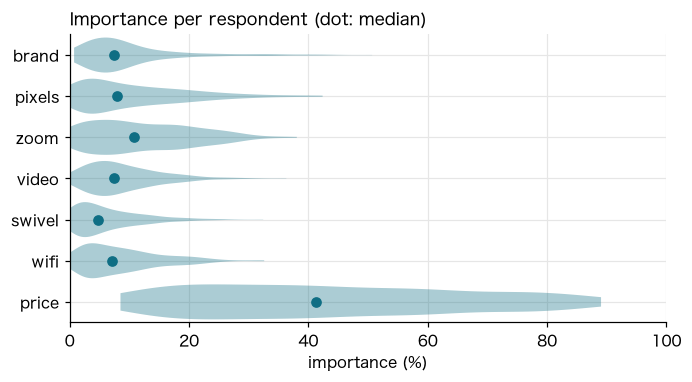

brand      9.7
pixels    10.7
zoom      12.1
video      8.9
swivel     6.4
wifi       8.7
price     43.6
dtype: float64

In [6]:
importance = result.importances()

fig, ax = plt.subplots(figsize=(7, 3.4))
parts = ax.violinplot([importance[a] for a in importance.columns], orientation="horizontal",
                      showextrema=False, widths=0.85)
for body in parts["bodies"]:
    body.set_facecolor(MAIN)
    body.set_alpha(0.35)
medians = importance.median()
ax.scatter(medians, np.arange(1, len(medians) + 1), color=MAIN, zorder=3)
ax.set_yticks(np.arange(1, len(medians) + 1), importance.columns)
ax.set_ylim(len(medians) + 0.5, 0.5)
ax.set_xlim(0, 100)
ax.set_xlabel("importance (%)")
ax.set_title("Importance per respondent (dot: median)")
plt.show()

importance.mean().round(1)

Price matters most, with about 44% on average. The features each take 6 to 12%. The
importance of price depends on the price range in the survey.

## 5. How much do respondents differ?

The next charts show the part-worth of each feature for all respondents. They pool the
posterior draws of every respondent, so they show the differences between respondents
and the uncertainty of the estimates together. The percentage in each title is the share of
all draws, pooled over respondents, where the part-worth is above zero.

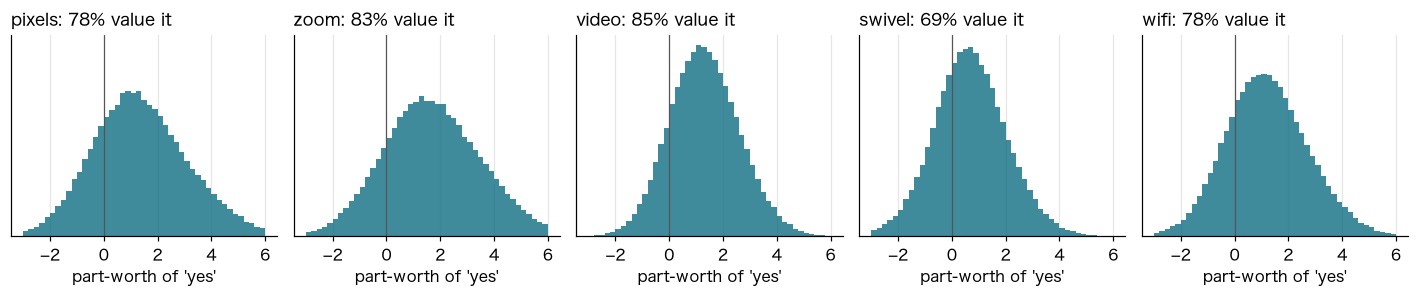

In [7]:
draws = result.beta_draws()[::10]                     # every tenth posterior draw
by_draw = data.codebook.expand(draws)
N = data.n_respondents


def per_respondent(column):
    """One column as an array: rows are draws, columns are respondents."""
    return by_draw[column].to_numpy().reshape(len(draws), N)


fig, axes = plt.subplots(1, len(FEATURES), figsize=(13, 2.8), sharex=True, sharey=True)
for ax, feature in zip(axes, FEATURES):
    values = per_respondent((feature, "yes"))
    ax.hist(values.ravel(), bins=np.linspace(-3, 6, 46), density=True, color=MAIN, alpha=0.8)
    ax.axvline(0, color="#555555", linewidth=0.8)
    ax.set_title(f"{feature}: {np.mean(values > 0):.0%} value it")
    ax.set_yticks([])
    ax.set_xlabel("part-worth of 'yes'")
plt.tight_layout()
plt.show()

For each feature, most draws are above zero, from 69% for swivel to 85% for video. But every
chart has a part below zero. A product with all features is not the best choice for
everyone, even before the price is counted.

## 6. What is each feature worth?

`wtp()` gives the willingness to pay for each feature: the price increase that cancels
out its gain. It reports the median respondent with a 90% credible interval.

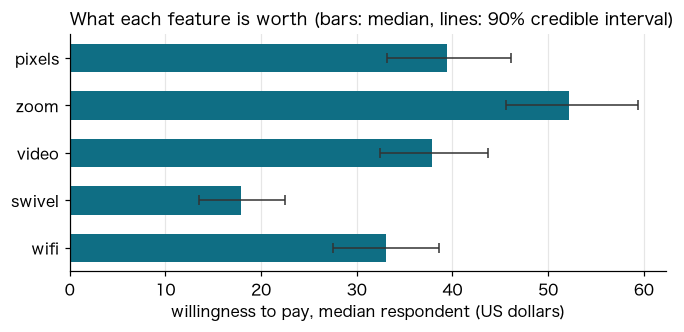

,median,lower,upper
attribute,,,
pixels,39.0,33.0,46.0
zoom,52.0,46.0,59.0
video,38.0,32.0,44.0
swivel,18.0,14.0,22.0
wifi,33.0,28.0,39.0


In [8]:
rows = [pw.wtp(result, attribute=f, from_level="no", to_level="yes") for f in FEATURES]
feature_wtp = pd.concat(rows).set_index("attribute")[["median", "lower", "upper"]] * 100   # hundreds of dollars to dollars

fig, ax = plt.subplots(figsize=(7, 2.8))
y = np.arange(len(feature_wtp))
ax.barh(y, feature_wtp["median"], color=MAIN, height=0.6)
ax.errorbar(feature_wtp["median"], y, fmt="none", ecolor="#333333", capsize=3, linewidth=1,
            xerr=[feature_wtp["median"] - feature_wtp["lower"],
                  feature_wtp["upper"] - feature_wtp["median"]])
ax.set_yticks(y, feature_wtp.index)
ax.set_ylim(len(y) - 0.5, -0.5)
ax.grid(axis="y", visible=False)
ax.set_xlabel("willingness to pay, median respondent (US dollars)")
ax.set_title("What each feature is worth (bars: median, lines: 90% credible interval)")
plt.show()

feature_wtp.round(0)

Zoom is worth about 52 dollars to the median respondent. Swivel is worth about 18
dollars. Swivel is clearly the least valued, because its interval lies below all the
others. Zoom is most likely the most valued, but its interval overlaps a little with that
of pixels.

## 7. Three cameras on the shelf

Put three cameras on a shelf and simulate how respondents choose.

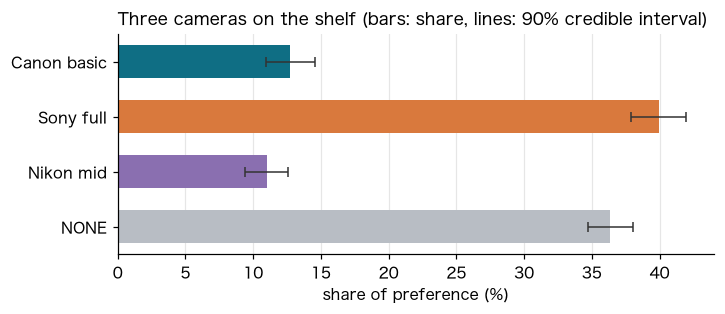

,share,lower,upper
product,,,
Canon basic,0.127,0.110,0.145
Sony full,0.399,0.379,0.420
Nikon mid,0.110,0.094,0.126
NONE,0.363,0.347,0.381


In [9]:
shelf = pd.DataFrame({
    "product": ["Canon basic", "Sony full", "Nikon mid"],
    "brand": ["canon", "sony", "nikon"],
    "pixels": ["no", "yes", "yes"],
    "zoom": ["no", "yes", "no"],
    "video": ["no", "yes", "yes"],
    "swivel": ["no", "yes", "no"],
    "wifi": ["no", "yes", "no"],
    "price": [1.29, 2.29, 1.79],          # hundreds of US dollars
})
sim = pw.MarketSimulator(result)
shares = sim.shares(shelf).set_index("product")

fig, ax = plt.subplots(figsize=(7, 2.6))
y = np.arange(len(shares))
ax.barh(y, shares["share"] * 100, color=[MAIN, ACCENT, "#8A6FB0", GREY], height=0.6)
ax.errorbar(shares["share"] * 100, y, fmt="none", ecolor="#333333", capsize=3, linewidth=1,
            xerr=[(shares["share"] - shares["lower"]) * 100,
                  (shares["upper"] - shares["share"]) * 100])
ax.set_yticks(y, shares.index)
ax.set_ylim(len(y) - 0.5, -0.5)
ax.grid(axis="y", visible=False)
ax.set_xlabel("share of preference (%)")
ax.set_title("Three cameras on the shelf (bars: share, lines: 90% credible interval)")
plt.show()

shares.round(3)

Sony full, with every feature at 229 dollars, is chosen by about 40%. Canon basic
at 129 dollars gets about 13%. About 36% choose none of the three.

## 8. How much can Wi-Fi add to the price?

Add Wi-Fi to Canon basic and raise its price in steps of 5 dollars. Both shelves use the
same posterior draws, so the change in share is taken draw by draw.

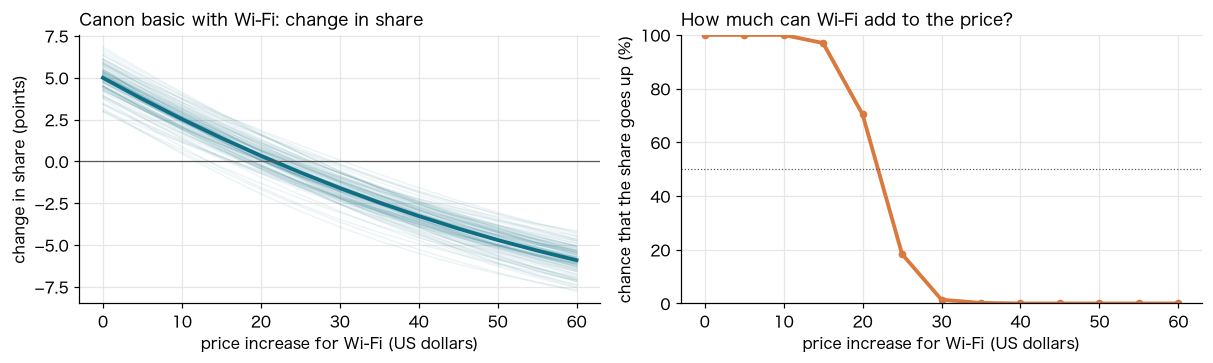

,change,lower,upper,chance_up
extra dollars,,,,
0,4.99,3.75,6.23,1.00
5,3.73,2.48,4.93,1.00
10,2.53,1.32,3.70,1.00
15,1.40,0.21,2.53,0.97
20,0.34,-0.78,1.46,0.70
25,-0.66,-1.78,0.47,0.18
30,-1.59,-2.73,-0.51,0.01
35,-2.46,-3.62,-1.32,0.00
40,-3.27,-4.47,-2.12,0.00


In [10]:
before = sim.share_draws(shelf)["Canon basic"].to_numpy()
extra = np.arange(0, 61, 5)                               # price increase in dollars
gain = []
for dollars in extra:
    upgraded = shelf.copy()
    upgraded.loc[0, ["wifi", "price"]] = ["yes", 1.29 + dollars / 100]
    gain.append((sim.share_draws(upgraded)["Canon basic"].to_numpy() - before) * 100)
gain = np.column_stack(gain)                               # rows: draws, columns: price increases

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.4))
left.plot(extra, gain[::5].T, color=MAIN, alpha=0.07, linewidth=1)
left.plot(extra, gain.mean(axis=0), color=MAIN, linewidth=2.5)
left.axhline(0, color="#555555", linewidth=0.8)
left.set_xlabel("price increase for Wi-Fi (US dollars)")
left.set_ylabel("change in share (points)")
left.set_title("Canon basic with Wi-Fi: change in share")
right.plot(extra, np.mean(gain > 0, axis=0) * 100, color=ACCENT, linewidth=2.5, marker="o",
           markersize=4)
right.axhline(50, color="#555555", linewidth=0.8, linestyle=":")
right.set_ylim(0, 100)
right.set_xlabel("price increase for Wi-Fi (US dollars)")
right.set_ylabel("chance that the share goes up (%)")
right.set_title("How much can Wi-Fi add to the price?")
plt.tight_layout()
plt.show()

pd.DataFrame({"change": gain.mean(axis=0), "lower": np.quantile(gain, 0.05, axis=0),
              "upper": np.quantile(gain, 0.95, axis=0),
              "chance_up": np.mean(gain > 0, axis=0)},
             index=pd.Index(extra, name="extra dollars")).round(2)

At the same price, Wi-Fi adds about 5 points of share. The gain shrinks as the price goes
up. At 20 dollars more, the share goes up in 70% of the draws. At 25 dollars more, it goes
up in only 18% of the draws. From 30 dollars, it goes down in almost every draw.

The break-even price increase, about 20 to 25 dollars, is lower than the willingness to
pay for Wi-Fi in step 6 (about 33 dollars). The two numbers answer different questions.
The willingness to pay is the price change that leaves the median respondent as happy as
before. The share depends on all respondents, and most of all on those who are close to
switching. In this data, the respondents close to switching to or from Canon basic are
more sensitive to price than the median respondent. So a price rise loses more of them.

## 9. The demand curve of Canon basic

Move the price of Canon basic over the range of the survey and keep the rest of the shelf
fixed. One thin line is one posterior draw.

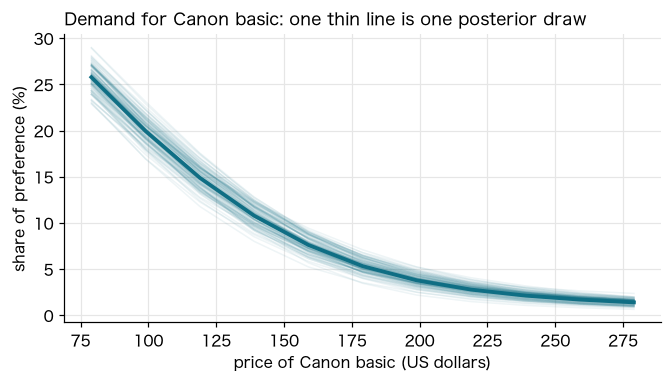

In [11]:
grid = np.round(np.arange(0.79, 2.80, 0.20), 2)            # 79 to 279 dollars in steps of 20


def canon_draws(price):
    """Share of Canon basic at one price, for every draw."""
    scenario = shelf.copy()
    scenario.loc[0, "price"] = price
    return sim.share_draws(scenario)["Canon basic"].to_numpy()


share_by_price = np.column_stack([canon_draws(p) for p in grid]) * 100

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(grid * 100, share_by_price[::5].T, color=MAIN, alpha=0.07, linewidth=1)
ax.plot(grid * 100, share_by_price.mean(axis=0), color=MAIN, linewidth=2.5)
ax.set_xlabel("price of Canon basic (US dollars)")
ax.set_ylabel("share of preference (%)")
ax.set_title("Demand for Canon basic: one thin line is one posterior draw")
plt.show()

The share falls from about 26% at 79 dollars to under 2% at 279 dollars. The thin lines
stay close together. The data pin down the price effect well.

## 10. Check the model with questions it did not see

`predict()` uses the fit from step 2 to predict the choices in questions 15 and 16.

In [12]:
scores = result.predict(test)                             # one row per respondent and hidden question
print(f"hit rate on questions 15 and 16: {scores['hit'].mean():.1%}")
print(f"guessing at random: {1 / 5:.0%}")

hit rate on questions 15 and 16: 73.8%
guessing at random: 20%


The model picks the right option in about 74% of the hidden questions. Guessing at random
gives 20%, because each question has five options.

The [validation report](../validation/results/camera_report.md) fits R bayesm on the same
split. It lets the price effect take either sign, as bayesm does, and it used an earlier
version of partworth. In that setting bayesm reaches 73.0% and partworth 72.9%, so the two
packages predict about equally well. This notebook keeps price negative, so its 74% comes
from a slightly different model.

## Next steps

- [retail_survey.ipynb](retail_survey.ipynb) works through a full study on dummy data,
  where the true answers are known.
- [docs/guide.md](../docs/guide.md) explains the choices you make along the way.